# 05 - Next-day PM2.5 forecast

**Question:** at the end of a day, can the next day's mean PM2.5 of each district be predicted better than by assuming that tomorrow equals today?

**Setup**
- **Unit:** one row per district and issue day *d*; the target is the daily mean PM2.5 of day *d+1* (rows with a missing target are dropped).
- **Features** (only data available at the end of day *d*): pollutant means of day *d*, PM2.5 lags of 1, 2, 3 and 6 days, a 7-day rolling mean, the city-wide mean of day *d* and its change from the day before, the day of year and weekday of the target day, and the station.
- **Split by time, never at random:** fit on targets in 2017-2018, evaluate on targets in 2019.
- **Validation inside 2017-2018:** four forecast origins, at the start of each quarter of 2018. Each fold fits on everything before its origin and validates on the following quarter, so the polluted first quarter is included. Settings, the choice of model and the alert threshold all come from these folds.
- **Metrics:** MAE (main), RMSE, bias, accuracy of the Korean grade, and precision / recall of the "Bad or worse" alert (a missed bad day is the costly error). A day is Bad or worse when its rounded mean is above 35 ug/m3, the same rule as the grade.

The whole procedure lives in `src/seoul_air/forecast.py` (`run_forecast`), with tests that check, among other things, that changing the 2019 targets changes none of the choices. This notebook runs it and explains the results.

**Status of 2019.** The 2019 results were inspected in earlier versions of this notebook and in the project review, before this protocol was fixed. Every choice below uses only 2017-2018, but the author has seen how the models perform in 2019, so 2019 is **no longer an untouched test**: its numbers are an evaluation after inspection and may be optimistic. A clean test needs data from 2020 onward.

## 1. Imports

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from seoul_air import config
import json

from sklearn.inspection import permutation_importance

from seoul_air.episodes import find_runs
from seoul_air.features import FEATURE_COLUMNS, make_forecast_table
from seoul_air.forecast import features, quarterly_folds, run_forecast, split_by_target_date
from seoul_air.metrics import alert, alert_scores, is_bad
from seoul_air.report import save_key_figures
sns.set_theme(style="whitegrid")
pd.set_option("display.width", 140)
config.FIGURES.mkdir(parents=True, exist_ok=True)
config.METRICS.mkdir(parents=True, exist_ok=True)

## 2. Forecast table and validation folds

In [2]:
daily = pd.read_parquet(config.DATA_PROCESSED / "air_daily.parquet")
table = make_forecast_table(daily)
table = table.dropna(subset=["target"]).reset_index(drop=True)

train, test = split_by_target_date(table)
print(f"Train: {len(train):,} rows, targets {train['target_date'].min().date()} to {train['target_date'].max().date()}")
print(f"Test:  {len(test):,} rows, targets {test['target_date'].min().date()} to {test['target_date'].max().date()}")
print("Test days evaluated:", test["target_date"].nunique(), "of 365")
print("Missing feature values in train (%):")
print(train[FEATURE_COLUMNS].isna().mean().mul(100).round(2)[lambda s: s > 0].to_string())

Train: 17,825 rows, targets 2017-01-02 to 2018-12-31
Test:  8,397 rows, targets 2019-01-01 to 2019-12-31
Test days evaluated: 347 of 365
Missing feature values in train (%):
pm25_d0             1.00
pm10_d0             1.24
no2_d0              0.96
co_d0               1.65
o3_d0               1.35
so2_d0              1.42
pm25_lag1           1.58
pm25_lag2           1.84
pm25_lag3           2.04
pm25_lag6           2.60
pm25_roll7          1.35
pm25_city_change    0.14


In [3]:
folds, fold_names = quarterly_folds(train["target_date"])
for (fit_idx, val_idx), name in zip(folds, fold_names):
    dates = train["target_date"].iloc[val_idx]
    print(f"{name}: fit {len(fit_idx):,} rows before {dates.min().date()} | validate to {dates.max().date()}: "
          f"{len(val_idx):,} rows, {100 * is_bad(train['target'].iloc[val_idx]).mean():.1f}% Bad or worse")

2018Q1: fit 8,906 rows before 2018-01-01 | validate to 2018-03-31: 2,175 rows, 34.0% Bad or worse
2018Q2: fit 11,081 rows before 2018-04-01 | validate to 2018-06-30: 2,243 rows, 17.6% Bad or worse
2018Q3: fit 13,324 rows before 2018-07-01 | validate to 2018-09-30: 2,259 rows, 0.4% Bad or worse
2018Q4: fit 15,583 rows before 2018-10-01 | validate to 2018-12-31: 2,242 rows, 15.9% Bad or worse


## 3. Baselines

- **Persistence:** tomorrow equals today (the 7-day mean, then the mean of the fit rows, when today is missing).
- **Climatology:** the mean of the fit rows for the same station and month of the target day.

## 4. Models and choice on validation

In [4]:
result = run_forecast(table)
selected = result["selected"]
for name, search in result["searches"].items():
    print(f"{name}: best settings {search.best_params_} | validation MAE {-search.best_score_:.3f}")
print("\nValidation MAE by fold (out of fold):")
print(result["by_fold"].round(3).to_string())
print("\nSelected model (lowest mean validation MAE):", selected)

ridge: best settings {'ridge__alpha': 100} | validation MAE 7.854
hist_gradient_boosting: best settings {'learning_rate': 0.03, 'loss': 'absolute_error', 'max_iter': 200, 'max_leaf_nodes': 15, 'min_samples_leaf': 80} | validation MAE 8.120

Validation MAE by fold (out of fold):
                ridge  hist_gradient_boosting  persistence
2018Q1         11.013                  11.410       12.533
2018Q2          7.830                   8.244        8.549
2018Q3          5.085                   5.104        4.855
2018Q4          7.487                   7.724        8.483
mean of folds   7.854                   8.120        8.605

Selected model (lowest mean validation MAE): ridge


**Interpretation.** The first quarter of 2018 is the hardest fold: 34.0% of its rows are Bad or worse and every model has its largest errors there (persistence 12.533 ug/m3). Ridge has the lowest MAE in three of the four folds and the lowest mean (7.854), ahead of gradient boosting (8.120) and persistence (8.605). In the clean third quarter (0.4% Bad or worse) persistence is best (4.855 against 5.085), so the gain of the model comes from the polluted and changing quarters. The tuned settings are Ridge with alpha 100, and boosting with a small learning rate, 15 leaves, 80 rows per leaf and absolute-error loss; boosting did not improve on the linear model with this data. Ridge is selected from these folds alone.

## 5. Alert threshold, calibrated on validation

A forecast shrinks towards the mean, so raising the alert only when it reaches 36 ug/m3 misses Bad days. The threshold is chosen on the out-of-fold forecasts of section 4 (2018), by the highest F1, with ties going to the higher threshold. Persistence gets its own calibrated threshold, so that the comparison stays fair. 2019 is not used.

In [5]:
validated = result["validated"]
y_val = result["train"]["target"].to_numpy()[validated]
rows = []
for name, (threshold, scores) in result["calibration"].items():
    default = alert_scores(is_bad(y_val), alert(result["oof"][name][validated]))
    chosen = scores.loc[scores["threshold"] == threshold].iloc[0]
    rows.append({"forecast": name, "threshold": threshold,
                 "f1_default": default["bad_f1"], "f1_calibrated": chosen["bad_f1"],
                 "recall_default": default["bad_recall"], "recall_calibrated": chosen["bad_recall"],
                 "precision_default": default["bad_precision"], "precision_calibrated": chosen["bad_precision"]})
print("Validation (2018, out of fold); default = alert when the forecast is graded Bad or worse")
pd.DataFrame(rows).set_index("forecast").round(3)

Validation (2018, out of fold); default = alert when the forecast is graded Bad or worse


,threshold,f1_default,f1_calibrated,recall_default,recall_calibrated,precision_default,precision_calibrated
forecast,,,,,,,
ridge,29.0,0.546,0.614,0.478,0.779,0.636,0.507
persistence,30.0,0.563,0.587,0.564,0.726,0.561,0.493


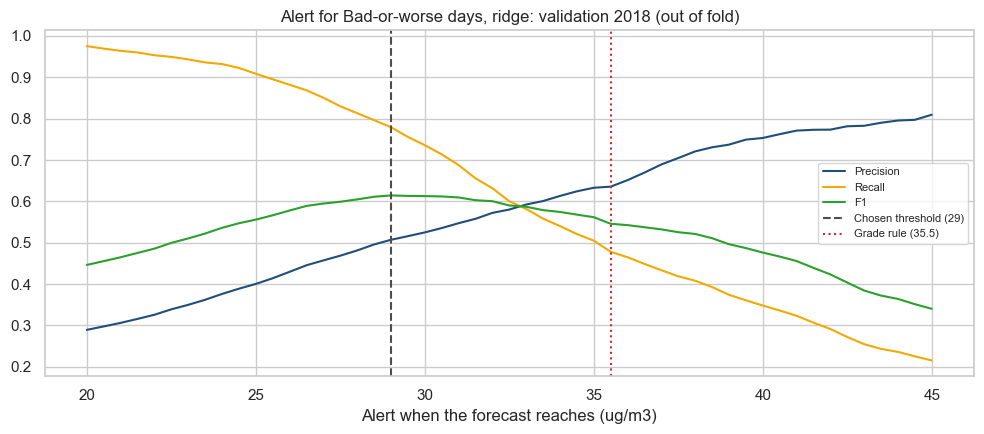

In [6]:
thresholds = result["thresholds"]
fig, ax = plt.subplots(figsize=(10, 4.5))
scores = result["calibration"][selected][1]
for column, color in [("bad_precision", "#1f4e79"), ("bad_recall", "#f2a900"), ("bad_f1", "#2ca02c")]:
    ax.plot(scores["threshold"], scores[column], color=color, label=column.replace("bad_", "").capitalize())
ax.axvline(thresholds[selected], color="0.3", ls="--", label=f"Chosen threshold ({thresholds[selected]:g})")
ax.axvline(35.5, color="#d62728", ls=":", label="Grade rule (35.5)")
ax.set_xlabel("Alert when the forecast reaches (ug/m3)")
ax.set_title(f"Alert for Bad-or-worse days, {selected}: validation 2018 (out of fold)")
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(config.FIGURES / "05_threshold_validation.png", dpi=120)
plt.show()

**Interpretation.** With the grade rule, the out-of-fold alert of Ridge is cautious: it catches 0.478 of the Bad-or-worse days of 2018 with a precision of 0.636. The threshold with the highest F1 is 29.0 ug/m3, which raises the recall to 0.779 at a precision of 0.507 and the F1 from 0.546 to 0.614. Persistence, given the same treatment, gets a threshold of 30.0 (F1 from 0.563 to 0.587). A lower threshold trades more false alarms for fewer missed Bad days. F1 weighs both errors equally; a service that cares more about missed Bad days would pick a lower threshold, along the curve above.

## 6. Evaluation on 2019 (inspected before, see the status note)

All choices are fixed above. Each model is fit on 2017-2018 with its chosen settings. The alert is scored twice: with the grade rule, and with the threshold calibrated on validation.

In [7]:
leaderboard, alerts_2019 = result["leaderboard"], result["alerts"]
predictions, y_test = result["predictions"], result["test"]["target"]
for name in leaderboard.index:
    record = {"evaluation_year": 2019, "inspected_before": True, **leaderboard.loc[name].to_dict()}
    if name in thresholds:
        calibrated = alerts_2019.loc[(name, "calibrated")]
        record["calibrated_alert"] = {"threshold": thresholds[name],
                                      **{k: calibrated[k] for k in ("bad_precision", "bad_recall", "bad_f1")}}
    (config.METRICS / f"05_{name}.json").write_text(json.dumps(record, indent=2))
leaderboard.to_csv(config.METRICS / "05_leaderboard.csv")
skill = 1 - leaderboard.loc[selected, "mae"] / leaderboard.loc["persistence", "mae"]
print(f"Selected model: {selected}; MAE improvement over persistence: {skill:.1%}")
leaderboard.round(3)

Selected model: ridge; MAE improvement over persistence: 10.0%


,mae,rmse,bias,grade_accuracy,bad_precision,bad_recall,bad_f1
model,,,,,,,
ridge,7.970,11.829,-1.089,0.653,0.704,0.534,0.607
hist_gradient_boosting,8.519,13.016,-1.308,0.648,0.695,0.517,0.593
persistence,8.859,13.093,0.038,0.638,0.612,0.606,0.609
climatology,10.832,16.437,-1.223,0.549,0.530,0.109,0.181


In [8]:
alerts_2019.to_csv(config.METRICS / "05_alerts_2019.csv")
alerts_2019.round(3)

threshold  bad_precision  bad_recall  bad_f1
forecast    alert                                                   
ridge       grade rule       35.5          0.704       0.534   0.607
            calibrated       29.0          0.548       0.760   0.637
persistence grade rule       35.5          0.612       0.606   0.609
            calibrated       30.0          0.522       0.739   0.612

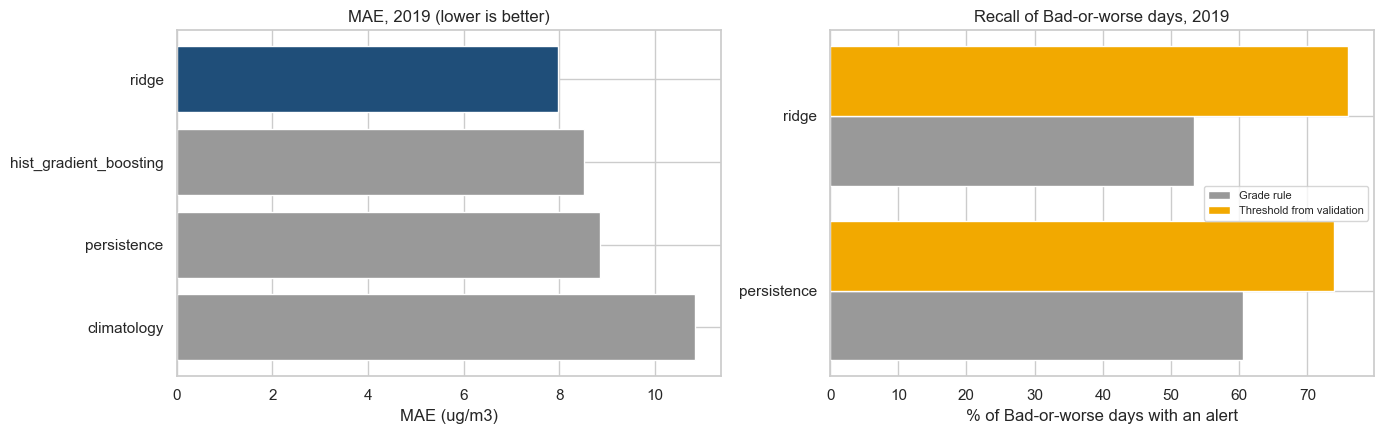

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
lb = leaderboard.sort_values("mae", ascending=False)
axes[0].barh(lb.index, lb["mae"], color=["#1f4e79" if i == selected else "0.6" for i in lb.index])
axes[0].set_title("MAE, 2019 (lower is better)")
axes[0].set_xlabel("MAE (ug/m3)")
a = alerts_2019["bad_recall"].unstack()
positions = np.arange(len(a))
axes[1].barh(positions - 0.2, a["grade rule"] * 100, height=0.4, color="0.6", label="Grade rule")
axes[1].barh(positions + 0.2, a["calibrated"] * 100, height=0.4, color="#f2a900", label="Threshold from validation")
axes[1].set_yticks(positions)
axes[1].set_yticklabels(a.index)
axes[1].set_title("Recall of Bad-or-worse days, 2019")
axes[1].set_xlabel("% of Bad-or-worse days with an alert")
axes[1].legend(fontsize=8)
fig.tight_layout()
fig.savefig(config.FIGURES / "05_leaderboard.png", dpi=120)
plt.show()

**Interpretation.** In 2019 Ridge has a MAE of 7.970 ug/m3, 10.0% lower than persistence (8.859), and is ahead of gradient boosting (8.519) and climatology (10.832), the same order as in validation. Its bias of -1.089 ug/m3 means that it predicts below the observed value on average. With the grade rule its alert is precise but misses Bad days: precision 0.704 and recall 0.534, against 0.612 and 0.606 for persistence. With the thresholds chosen on validation, Ridge reaches a recall of 0.760 at a precision of 0.548 (F1 0.637), and persistence 0.739 and 0.522 (F1 0.612). These are figures for a year that had already been inspected (see the status note), so they may be optimistic.

## 7. Uncertainty: block bootstrap by week

The 25 stations of the same day, and the days of the same week, are not independent: there are far fewer independent cases than rows. The bootstrap resamples whole weeks of 2019 (all stations and days of a week together) and scores both forecasts on the same draw, which gives 95% intervals for their differences.

In [10]:
intervals = result["intervals"]
intervals.to_csv(config.METRICS / "05_bootstrap_intervals.csv", index=False)
print("Rows:", len(result["test"]), "| weeks:", result["weeks"].nunique())
print(f"{selected} minus persistence; skill = 1 - MAE ratio")
intervals.round(4)

Rows: 8397 | weeks: 52
ridge minus persistence; skill = 1 - MAE ratio


,statistic,alert,low_95,high_95,excludes_zero
0,mae_diff,,-1.5414,-0.3512,True
1,skill,,0.0425,0.1564,True
2,recall_diff,grade rule,-0.1373,-0.0183,True
3,recall_diff,calibrated,-0.0409,0.0808,False


**Interpretation.** The intervals use 52 weeks, not 8,397 independent rows. The gain in error size is robust: Ridge's MAE is between 0.351 and 1.541 ug/m3 lower than that of persistence, a skill of 4.3% to 15.6%. With the grade rule, its loss of recall is also real: between 1.8 and 13.7 percentage points below persistence. With the calibrated thresholds the interval runs from -4.1 to +8.1 points: Ridge no longer misses more Bad days than persistence, but there is no evidence that it catches more. **Conclusion:** the model predicts the level of PM2.5 better than persistence; as an alert it is only as good as persistence once its threshold is calibrated.

## 8. Error analysis

MAE by month of the target day, 2019:
target_date     1      2      3      4      5      6      7      8      9      10     11     12
days         31.00  28.00  22.00  30.00  28.00  30.00  29.00  31.00  27.00  31.00  30.00  30.00
ridge        12.93   9.62  17.52   6.73   9.68   6.90   7.26   4.36   3.94   4.77   5.59   7.77
persistence  15.34  10.89  18.29   6.17  10.86   7.96   7.47   5.15   4.03   5.98   6.35   9.03


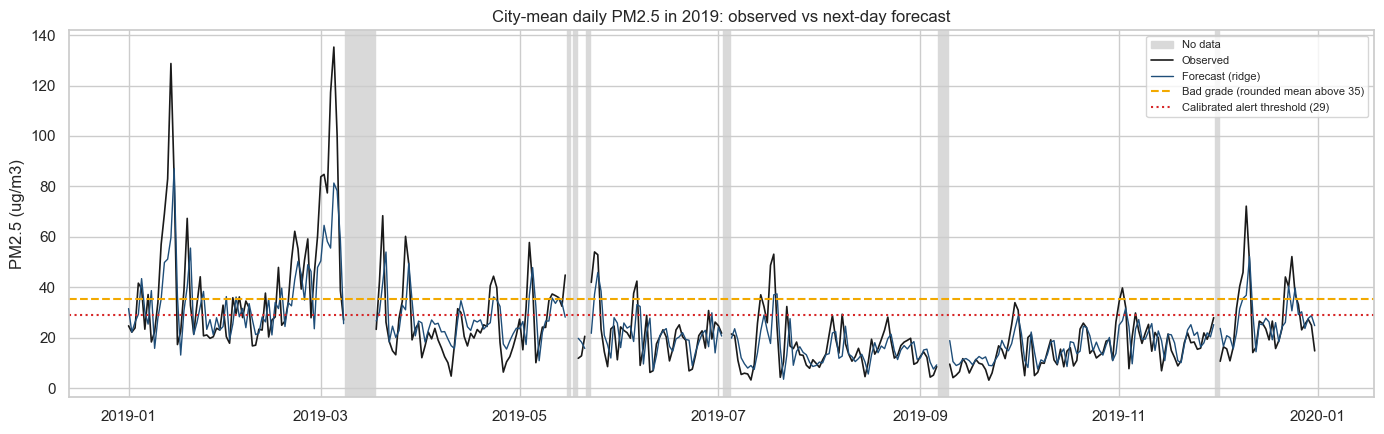

In [11]:
res = result["test"][["station_code", "target_date", "target"]].copy()
res["pred"] = predictions[selected]
res["persistence"] = predictions["persistence"]
res["abs_err"] = (res["pred"] - res["target"]).abs()
res["abs_err_persistence"] = (res["persistence"] - res["target"]).abs()

by_month = res.groupby(res["target_date"].dt.month)[["abs_err", "abs_err_persistence"]].mean()
by_month.columns = [selected, "persistence"]
by_month.insert(0, "days", res.groupby(res["target_date"].dt.month)["target_date"].nunique())
print("MAE by month of the target day, 2019:")
print(by_month.round(2).T.to_string())

# Reindex to every day of 2019 so that the lines stop at the days without data
days_2019 = pd.date_range("2019-01-01", "2019-12-31", freq="D")
city_res = res.groupby("target_date")[["target", "pred", "persistence"]].mean().reindex(days_2019)
fig, ax = plt.subplots(figsize=(14, 4.5))
for gap in find_runs(city_res["target"].isna()).itertuples():
    ax.axvspan(gap.start - pd.Timedelta(hours=12), gap.end + pd.Timedelta(hours=12),
               color="0.85", zorder=0, label="No data" if gap.Index == 0 else None)
ax.plot(city_res.index, city_res["target"], color="k", lw=1.2, label="Observed")
ax.plot(city_res.index, city_res["pred"], color="#1f4e79", lw=1, label=f"Forecast ({selected})")
ax.axhline(35.5, color="#f2a900", ls="--", label="Bad grade (rounded mean above 35)")
ax.axhline(thresholds[selected], color="#d62728", ls=":", label=f"Calibrated alert threshold ({thresholds[selected]:g})")
ax.set_title("City-mean daily PM2.5 in 2019: observed vs next-day forecast")
ax.set_ylabel("PM2.5 (ug/m3)")
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(config.FIGURES / "05_forecast_2019.png", dpi=120)
plt.show()

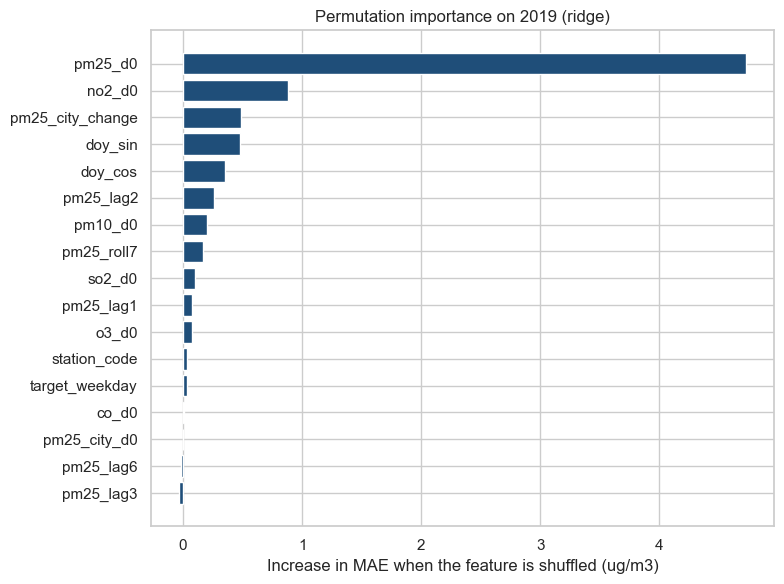

pm25_d0             4.727
no2_d0              0.885
pm25_city_change    0.488
doy_sin             0.475
doy_cos             0.351


In [12]:
model = result["searches"][selected].best_estimator_
imp = permutation_importance(model, features(result["test"], selected), y_test, n_repeats=5,
                             random_state=42, scoring="neg_mean_absolute_error")
importance = pd.Series(imp.importances_mean, index=FEATURE_COLUMNS).sort_values()
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(importance.index, importance.values, color="#1f4e79")
ax.set_title(f"Permutation importance on 2019 ({selected})")
ax.set_xlabel("Increase in MAE when the feature is shuffled (ug/m3)")
fig.tight_layout()
fig.savefig(config.FIGURES / "05_feature_importance.png", dpi=120)
plt.show()
print(importance.sort_values(ascending=False).head(5).round(3).to_string())

**Interpretation.** Errors are largest in the high-pollution months (Ridge MAE 17.52 in March, on 22 evaluated days, and 12.93 in January) and smallest in September (3.94, on 27 days). Ridge beats persistence in 11 of the 12 months; the exception is April (6.73 against 6.17). The most important feature by far is today's PM2.5 (shuffling it raises the MAE by 4.727), followed by today's NO2 (0.885), the city-wide change from the day before (0.488) and the season (day of year). These importances suggest that the model relies mostly on persistence. The dataset has no weather variables, so it cannot show what explains the remaining errors.

## 9. Key figures

In [13]:
grade_rule = alerts_2019.xs("grade rule", level="alert")
calibrated = alerts_2019.xs("calibrated", level="alert")
skill_interval = intervals.set_index(["statistic", "alert"]).loc[("skill", "")]
save_key_figures("05", {
    "selected_model": selected,
    "mae": leaderboard["mae"].to_dict(),
    "skill_vs_persistence_pct": 100 * skill,
    "skill_interval_pct": [100 * skill_interval["low_95"], 100 * skill_interval["high_95"]],
    "recall_grade_rule": grade_rule["bad_recall"].to_dict(),
    "recall_calibrated": calibrated["bad_recall"].to_dict(),
    "threshold": thresholds,
    "validation_mae": result["by_fold"].loc["mean of folds"].to_dict(),
})
print(json.dumps(json.loads((config.METRICS / "05_key_figures.json").read_text()), indent=1))

{
 "mae": {
  "climatology": 10.831581506234054,
  "hist_gradient_boosting": 8.51865474351821,
  "persistence": 8.858835883480342,
  "ridge": 7.970105499085755
 },
 "recall_calibrated": {
  "persistence": 0.7392784206943499,
  "ridge": 0.7597004765146358
 },
 "recall_grade_rule": {
  "persistence": 0.6058543226684819,
  "ridge": 0.5336963921034718
 },
 "selected_model": "ridge",
 "skill_interval_pct": [
  4.251304417688282,
  15.64479322314407
 ],
 "skill_vs_persistence_pct": 10.032135103121863,
 "threshold": {
  "persistence": 30.0,
  "ridge": 29.0
 },
 "validation_mae": {
  "hist_gradient_boosting": 8.120322618902115,
  "persistence": 8.605080585872777,
  "ridge": 7.853867425947419
 }
}


## 10. Limitations

- **2019 has been inspected.** It is an evaluation after inspection, not an untouched test (see the status note at the top).
- **No weather data.** Wind, rain and humidity are not in the dataset, so their role in day-to-day PM2.5 changes cannot be measured or used. Adding KMA observations and weather forecasts for day *d+1* is the main next step.
- **Three years only.** The first validation fold fits on a single year, and the model has seen each season at most twice.
- **Daily means, issued at midnight.** An operational forecast would be issued earlier (for example at 17:00 KST) with fewer hours of day *d*.
- **One station per district.** District values are station values and may not represent the whole district.